<hr style="border: none; border-top: 2px solid #ccc; margin: 30px 0;">

<h1 style="
  text-align: center;
  font-weight: 600;
  color: #2c3e50;
  margin: 0;
">
  I. Classification
    
</h1>

<hr style="border: none; border-top: 2px solid #ccc; margin: 30px 0;">

### Import des librairies

In [1]:
from sklearn import datasets
from skimpy import skim
import pandas as pd
import plotly.express as px

from src.missingvalues import (
    missing_values_summary,
    missing_values_heatmap
)

### Import du *dataset*

In [2]:
iris = datasets.load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)

df['target'] = iris.target
df['species'] = df['target'].map({i: name for i, name in enumerate(iris.target_names)})

df = df.drop(columns='target')

### Synthèse statistique

In [3]:
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [4]:
skim(df)

╭──────────────────────────────────────────────── skimpy summary ─────────────────────────────────────────────────╮
│          Data Summary                Data Types                                                                 │
│ ┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┓ ┏━━━━━━━━━━━━━┳━━━━━━━┓                                                          │
│ ┃ Dataframe         ┃ Values ┃ ┃ Column Type ┃ Count ┃                                                          │
│ ┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━┩ ┡━━━━━━━━━━━━━╇━━━━━━━┩                                                          │
│ │ Number of rows    │ 150    │ │ float64     │ 4     │                                                          │
│ │ Number of columns │ 5      │ │ string      │ 1     │                                                          │
│ └───────────────────┴────────┘ └─────────────┴───────┘                                                          │
│                                                     number                                                      │
│ ┏━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━┳━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━┳━━━━━━┳━━━━━━┳━━━━━━━━┳━━━━━━┳━━━━━━━┳━━━━━━━━━┓  │
│ ┃ column                 ┃ NA  ┃ NA %   ┃ mean    ┃ sd       ┃ p0   ┃ p25  ┃ p50    ┃ p75  ┃ p100  ┃ hist    ┃  │
│ ┡━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━╇━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━╇━━━━━━╇━━━━━━╇━━━━━━━━╇━━━━━━╇━━━━━━━╇━━━━━━━━━┩  │
│ │ sepal length (cm)      │   0 │      0 │   5.843 │   0.8281 │  4.3 │  5.1 │    5.8 │  6.4 │   7.9 │ ▃██▇▅▂  │  │
│ │ sepal width (cm)       │   0 │      0 │   3.057 │   0.4359 │    2 │  2.8 │      3 │  3.3 │   4.4 │ ▁▇█▇▂▁  │  │
│ │ petal length (cm)      │   0 │      0 │   3.758 │    1.765 │    1 │  1.6 │   4.35 │  5.1 │   6.9 │ █ ▂▇▆▂  │  │
│ │ petal width (cm)       │   0 │      0 │   1.199 │   0.7622 │  0.1 │  0.3 │    1.3 │  1.8 │   2.5 │ █ ▂▆▄▄  │  │
│ └────────────────────────┴─────┴────────┴─────────┴──────────┴──────┴──────┴────────┴──────┴───────┴─────────┘  │
│                                                     string                                                      │
│ ┏━━━━━━━━━┳━━━━┳━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━┓  │
│ ┃         ┃    ┃      ┃          ┃            ┃        ┃           ┃ chars per   ┃ words per   ┃             ┃  │
│ ┃ column  ┃ NA ┃ NA % ┃ shortest ┃ longest    ┃ min    ┃ max       ┃ row         ┃ row         ┃ total words ┃  │
│ ┡━━━━━━━━━╇━━━━╇━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━┩  │
│ │ species │  0 │    0 │ setosa   │ versicolor │ setosa │ virginica │        8.33 │           1 │         150 │  │
│ └─────────┴────┴──────┴──────────┴────────────┴────────┴───────────┴─────────────┴─────────────┴─────────────┘  │
╰────────────────────────────────────────────────────── End ──────────────────────────────────────────────────────╯

In [5]:
missing_values_summary(df)

,Nb NaN (Manquant),% NaN,Nb zéros,% zéros,Total Lignes
sepal length (cm),0,0.0,0,0.0,150
sepal width (cm),0,0.0,0,0.0,150
petal length (cm),0,0.0,0,0.0,150
petal width (cm),0,0.0,0,0.0,150


### Gestion des valeurs manquantes

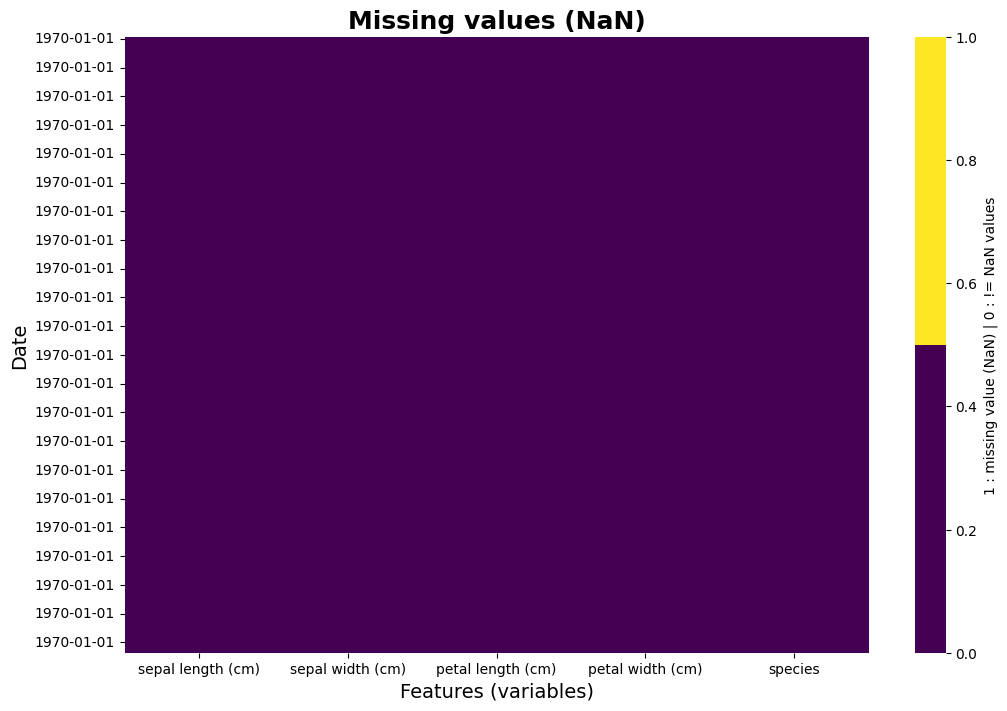

In [6]:
missing_values_heatmap(df, method='nan')

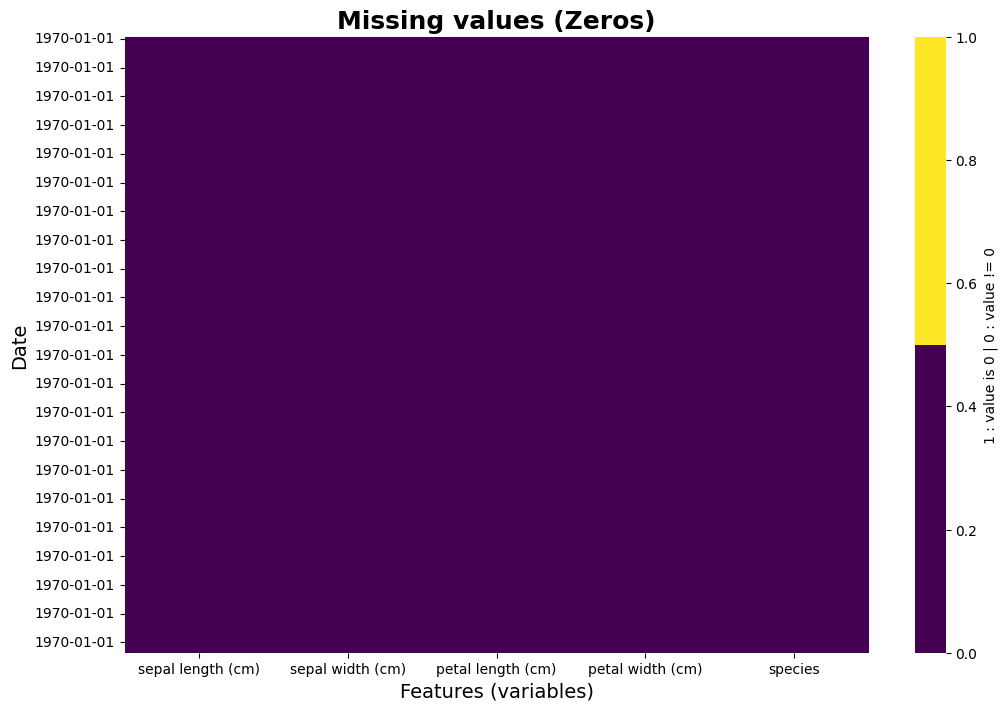

In [7]:
missing_values_heatmap(df, method='zeros')

### Scatter plot

<hr style="border: none; border-top: 2px solid #ccc; margin: 30px 0;">

<h1 style="
  text-align: center;
  font-weight: 600;
  color: #2c3e50;
  margin: 0;
">
  II. Time series
    
</h1>

<hr style="border: none; border-top: 2px solid #ccc; margin: 30px 0;">

### Import des librairies

In [38]:
from sklearn import datasets
from skimpy import skim
import pandas as pd
import plotly.express as px
from itertools import cycle
import numpy as np

from src.missingvalues import (
    missing_values_summary,
    missing_values_heatmap
)

### Import du *dataset*

In [39]:
df = pd.read_csv("data/ETTh.csv")

In [40]:
df.head()

,date,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT
0,2016-07-01 00:00:00,5.827,2.009,1.599,0.462,4.203,1.340,30.531000
1,2016-07-01 01:00:00,5.693,2.076,1.492,0.426,4.142,1.371,27.787001
2,2016-07-01 02:00:00,5.157,1.741,1.279,0.355,3.777,1.218,27.787001
3,2016-07-01 03:00:00,5.090,1.942,1.279,0.391,3.807,1.279,25.044001
4,2016-07-01 04:00:00,5.358,1.942,1.492,0.462,3.868,1.279,21.948000


In [41]:
skim(df)

╭──────────────────────────────────────────────── skimpy summary ─────────────────────────────────────────────────╮
│          Data Summary                Data Types                                                                 │
│ ┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┓ ┏━━━━━━━━━━━━━┳━━━━━━━┓                                                          │
│ ┃ Dataframe         ┃ Values ┃ ┃ Column Type ┃ Count ┃                                                          │
│ ┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━┩ ┡━━━━━━━━━━━━━╇━━━━━━━┩                                                          │
│ │ Number of rows    │ 17420  │ │ float64     │ 7     │                                                          │
│ │ Number of columns │ 8      │ │ string      │ 1     │                                                          │
│ └───────────────────┴────────┘ └─────────────┴───────┘                                                          │
│                                                     number                                                      │
│ ┏━━━━━━━━━━┳━━━━━┳━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━┓  │
│ ┃ column   ┃ NA  ┃ NA %   ┃ mean     ┃ sd       ┃ p0       ┃ p25      ┃ p50     ┃ p75     ┃ p100   ┃ hist    ┃  │
│ ┡━━━━━━━━━━╇━━━━━╇━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━╇━━━━━━━━━┩  │
│ │ HUFL     │   0 │      0 │    7.375 │    7.068 │   -22.71 │    5.827 │   8.774 │   11.79 │  23.64 │  ▁▁▅█▁  │  │
│ │ HULL     │   0 │      0 │    2.242 │    2.042 │   -4.756 │    0.737 │    2.21 │   3.684 │  10.11 │   ▃█▆▁  │  │
│ │ MUFL     │   0 │      0 │      4.3 │    6.827 │   -25.09 │    3.296 │    5.97 │   8.635 │  17.34 │  ▁▁▂█▁  │  │
│ │ MULL     │   0 │      0 │   0.8816 │    1.809 │   -5.934 │   -0.284 │   0.959 │   2.203 │  7.747 │   ▃▇█▂  │  │
│ │ LUFL     │   0 │      0 │    3.066 │    1.165 │   -1.188 │    2.315 │   2.833 │   3.625 │  8.498 │   ▂█▃   │  │
│ │ LULL     │   0 │      0 │   0.8569 │   0.5996 │   -1.371 │     0.67 │   0.975 │   1.218 │  3.046 │  ▁▁▄█▁  │  │
│ │ OT       │   0 │      0 │    13.32 │    8.567 │    -4.08 │    6.964 │    11.4 │   18.08 │  46.01 │  ▂█▅▂▁  │  │
│ └──────────┴─────┴────────┴──────────┴──────────┴──────────┴──────────┴─────────┴─────────┴────────┴─────────┘  │
│                                                     string                                                      │
│ ┏━━━━━━━━┳━━━━┳━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━┓  │
│ ┃        ┃    ┃      ┃            ┃           ┃            ┃           ┃ chars per  ┃ words per ┃ total      ┃  │
│ ┃ column ┃ NA ┃ NA % ┃ shortest   ┃ longest   ┃ min        ┃ max       ┃ row        ┃ row       ┃ words      ┃  │
│ ┡━━━━━━━━╇━━━━╇━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━┩  │
│ │ date   │  0 │    0 │ 2016-07-01 │ 2016-07-0 │ 2016-07-01 │ 2018-06-2 │         19 │         2 │      34840 │  │
│ │        │    │      │ 00:00:00   │ 1         │ 00:00:00   │ 6         │            │           │            │  │
│ │        │    │      │            │ 00:00:00  │            │ 19:00:00  │            │           │            │  │
│ └────────┴────┴──────┴────────────┴───────────┴────────────┴───────────┴────────────┴───────────┴────────────┘  │
╰────────────────────────────────────────────────────── End ──────────────────────────────────────────────────────╯

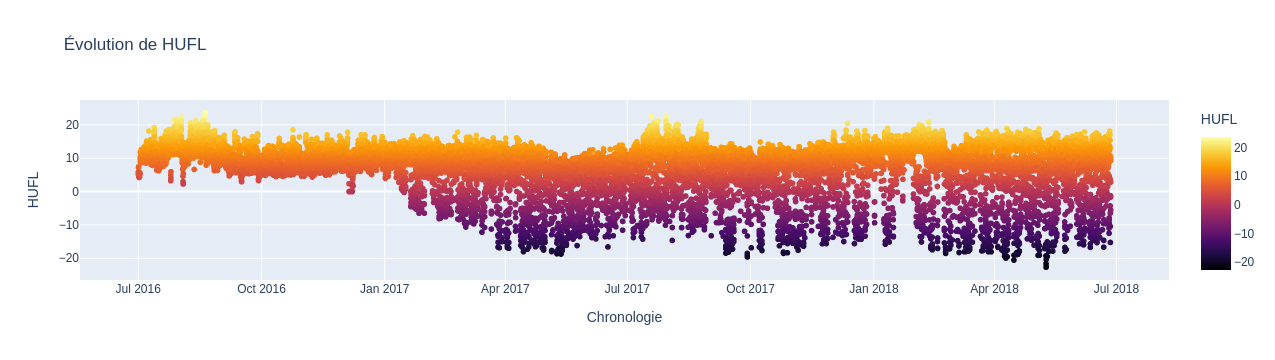

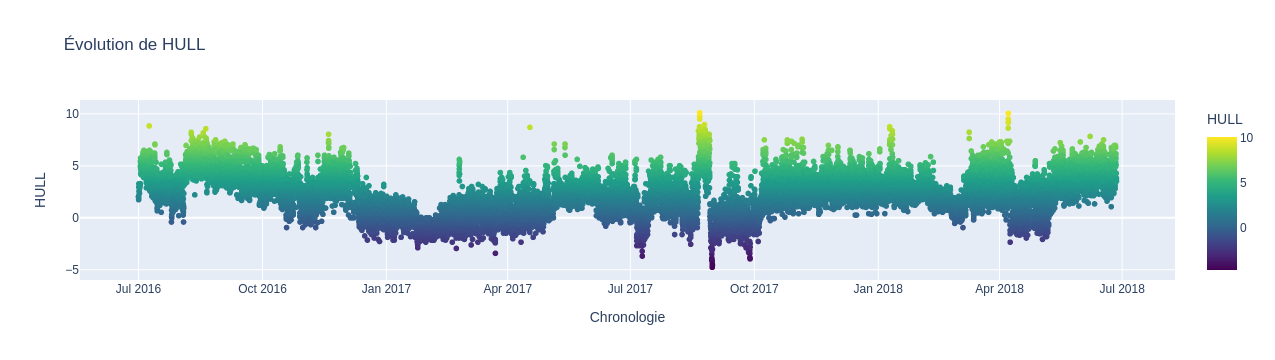

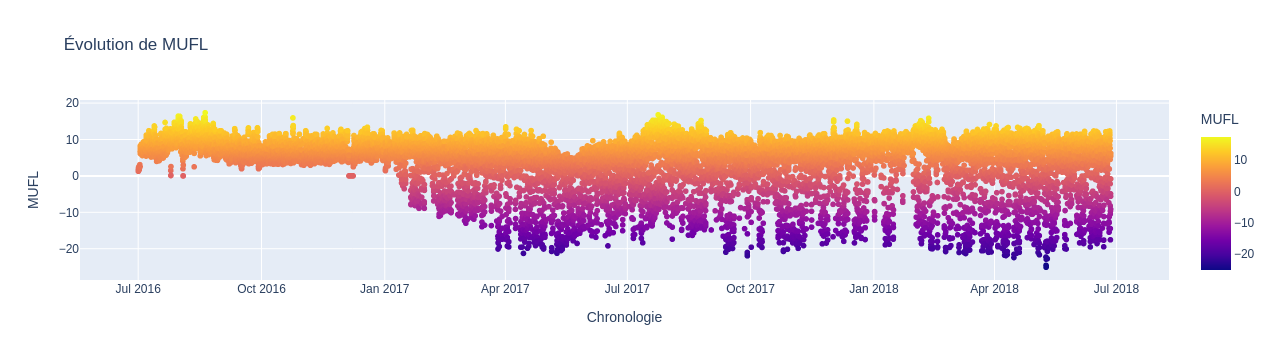

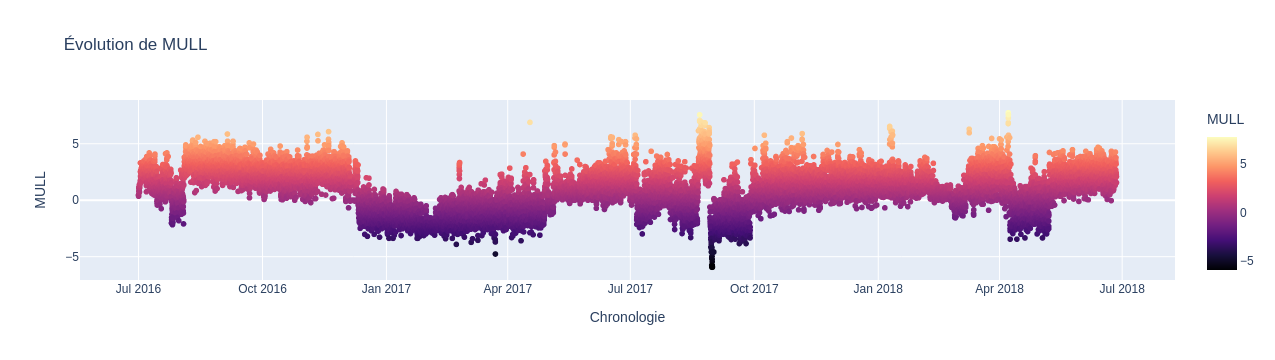

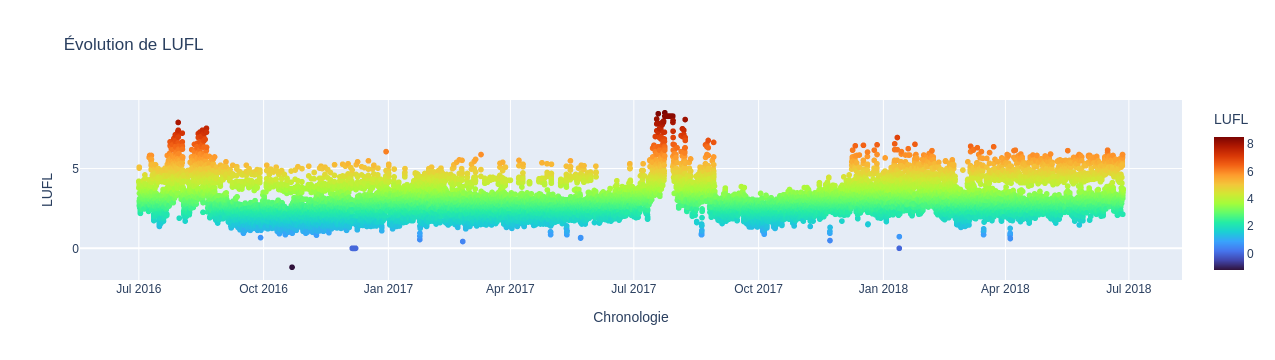

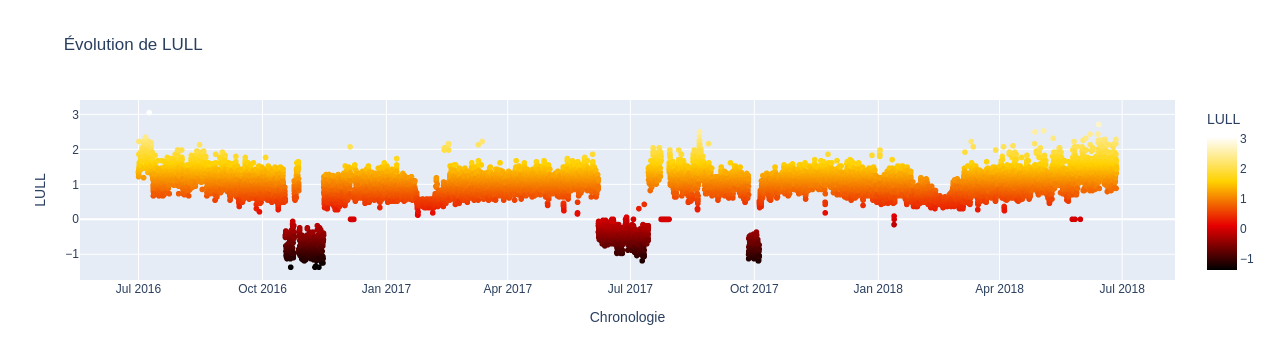

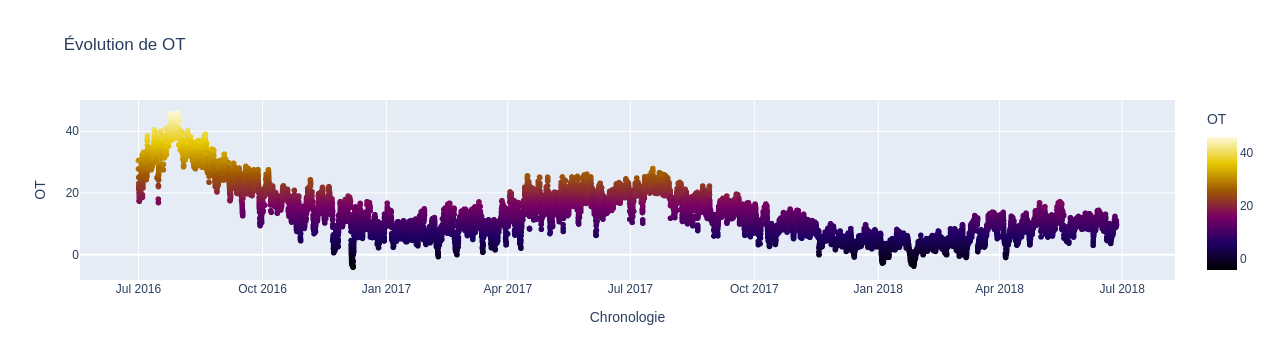

In [42]:
features = df.select_dtypes(include=[np.number, 'timedelta64']).columns
cmaps_cycle = cycle([
    'Inferno',
    'Viridis',
    'Plasma',
    'Magma',
    'Turbo',
    'Hot', 
    'Electric'
])

for feature in features:
    current_cmap = next(cmaps_cycle)

    y_values = df[feature]
    if 'timedelta' in str(y_values.dtype):
        y_values = y_values.dt.total_seconds() / 3600
    

    fig = px.scatter(
        df,
        x='date',
        y=y_values,
        color=y_values,
        color_continuous_scale=current_cmap,
        title=f"Évolution de {feature}"
    )
    
    fig.update_traces(
        line=dict(width=2),
        connectgaps=False
    )
    
    fig.update_layout(
        #template="plotly_dark",
        xaxis_title="Chronologie",
        yaxis_title=feature,
        coloraxis_showscale=True,
        hovermode="x unified"
    )
    
    fig.show()